# Prelude

In [40]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [41]:
seaborn.set()

# Getting Data

In [42]:
data = pandas.read_csv(
    'results/results_1m_300.csv',
    index_col = ['problem', 'strategy'],
)
data = data[data.index.get_level_values('strategy') != 'InitialSchedule']

In [43]:
strategies = data.index.get_level_values('strategy').unique()

In [44]:
strategies

Index(['FirstAction', 'LeanCopCut', 'HeuristicSelection', 'SubgoalReordering',
       'EntropyCut', 'AdaptiveReset', 'SmartCut'],
      dtype='object', name='strategy')

# Analysing

In [45]:
control = ['FirstAction', 'LeanCopCut']

In [46]:
data[data.solved]

status  solved     steps  time_ms     info  \
problem    strategy                                                         
AGT001+1.p FirstAction         solved    True       4.0      1.0      NaN   
           LeanCopCut          solved    True       4.0      1.0      NaN   
           HeuristicSelection  solved    True       2.0      2.0      NaN   
           SubgoalReordering   solved    True       2.0      2.0      NaN   
           EntropyCut          solved    True       4.0      2.0      NaN   
...                               ...     ...       ...      ...      ...   
TOP026+1.p LeanCopCut          solved    True  312965.0  71905.0  Theorem   
TOP027+1.p LeanCopCut          solved    True  345460.0  82535.0  Theorem   
TOP034+1.p FirstAction         solved    True  371162.0  61525.0  Theorem   
           LeanCopCut          solved    True  271594.0  72620.0  Theorem   
           AdaptiveReset       solved    True  371162.0  74594.0  Theorem   

                              error  
problem    strategy                  
AGT001+1.p FirstAction          NaN  
           LeanCopCut           NaN  
           HeuristicSelection   NaN  
           SubgoalReordering    NaN  
           EntropyCut           NaN  
...                             ...  
TOP026+1.p LeanCopCut           NaN  
TOP027+1.p LeanCopCut           NaN  
TOP034+1.p FirstAction          NaN  
           LeanCopCut           NaN  
           AdaptiveReset        NaN  

[14438 rows x 6 columns]

In [47]:
data[data.solved].groupby(level = 1).size()

strategy
AdaptiveReset         1629
EntropyCut            2225
FirstAction           2208
HeuristicSelection    2138
LeanCopCut            2467
SmartCut              1629
SubgoalReordering     2142
dtype: int64

In [48]:
solved = data['solved'].unstack('strategy')

In [49]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction             7
LeanCopCut            314
HeuristicSelection      0
SubgoalReordering       4
EntropyCut             17
AdaptiveReset           1
SmartCut                1
dtype: int64

# Schedules

## 300 Seconds

In [132]:
schedule_300s = Series(
    index = ['AdaptiveReset', 'EntropyCut', 'SmartCut', 'SubgoalReordering'],
    data = [x * 1000 for x in [1, 126, 5, 162]],
)

In [135]:
times = data.time_ms.unstack()
solve_schedule_300s = ((times[schedule_300s.index] <= schedule_300s).fillna(False) & solved[schedule_300s.index]).any(axis = 1).rename('Schedule')

In [138]:
pandas.concat([solved.LeanCopCut, solve_schedule_300s], axis = 1).value_counts()

LeanCopCut  Schedule
False       False       23098
True        True         2117
            False         350
False       True          210
Name: count, dtype: int64

## 60 Seconds

In [140]:
schedule_60s = Series(
    index = ['AdaptiveReset', 'SubgoalReordering', 'EntropyCut', 'SmartCut'],
    data = [x * 1000 for x in [1, 4, 53, 2]],
)

In [141]:
solve_schedule_60s = ((times[schedule_60s.index] <= schedule_60s).fillna(False) & solved[schedule_60s.index]).any(axis = 1).rename('Schedule')

In [142]:
pandas.concat([solved.LeanCopCut, solve_schedule_60s], axis = 1).value_counts()

LeanCopCut  Schedule
False       False       23177
True        True         1981
            False         486
False       True          131
Name: count, dtype: int64

# New Strategies

In [20]:
schedules = {d['name']: d['slots'] for x in glob.glob('schedules/portfolio_*.json') for d in [json.load(open(x))]}

In [21]:
schedules

{'Portfolio120Total': [{'strategy': 'SubgoalReordering',
   'time_budget_ms': 3705},
  {'strategy': 'AdaptiveReset', 'time_budget_ms': 4588},
  {'strategy': 'LeanCopCut', 'time_budget_ms': 95539},
  {'strategy': 'HeuristicReductionCut', 'time_budget_ms': 581},
  {'strategy': 'EntropyCut', 'time_budget_ms': 13619},
  {'strategy': 'GoalDistanceCut', 'time_budget_ms': 1584},
  {'strategy': 'DepthPhasedCut', 'time_budget_ms': 339}],
 'Portfolio120Novel': [{'strategy': 'SmartCut', 'time_budget_ms': 863},
  {'strategy': 'SubgoalReordering', 'time_budget_ms': 13410},
  {'strategy': 'DepthPhasedCut', 'time_budget_ms': 31596},
  {'strategy': 'HeuristicReductionCut', 'time_budget_ms': 581},
  {'strategy': 'GoalDistanceCut', 'time_budget_ms': 1584},
  {'strategy': 'EntropyCut', 'time_budget_ms': 43111},
  {'strategy': 'AdaptiveReset', 'time_budget_ms': 4588},
  {'strategy': 'ReductionCut', 'time_budget_ms': 23446}],
 'Portfolio60Total': [{'strategy': 'AdaptiveReset', 'time_budget_ms': 435},
  {'s

In [123]:
violin = pandas.read_csv('results/schedule_violin_data.csv')
violin['schedule'].replace(
    {
        'Portfolio60Total': 'P1 60s',
        'Portfolio60Novel': 'P2 60s',
        'Portfolio120Total': 'P1 120s',
        'Portfolio120Novel': 'P2 120s',
    },
    inplace = True,
)
violin.sort_values('schedule', inplace = True)

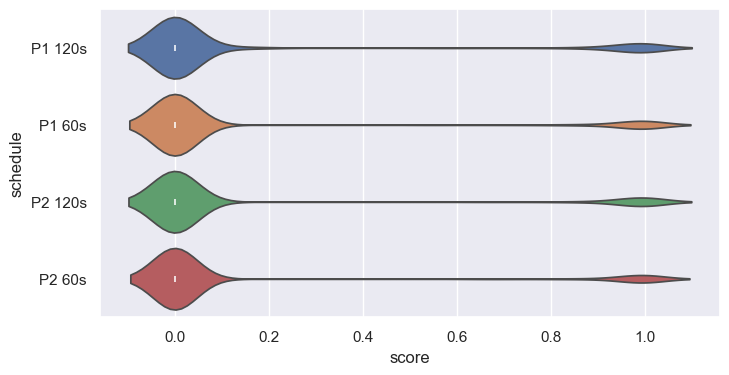

In [148]:
pyplot.rcParams['figure.figsize'] = (8, 4)
seaborn.violinplot(
    violin[violin.terminal_status != 'error'],
    x = 'score',
    y = 'schedule',
    hue = 'schedule',
)
pyplot.savefig('plots/schedule_violinplots.png', dpi = 400, bbox_inches = 'tight')

In [137]:
leancop = data.xs('LeanCopCut', level = 1)
leancop_60s_score = ((60000 - leancop.time_ms) / 60000).where((leancop.time_ms <= 60000) & (leancop.solved), 0).rename('score')
leancop_120s_score = ((120000 - leancop.time_ms) / 120000).where((leancop.time_ms <= 120000) & (leancop.solved), 0).rename('score')

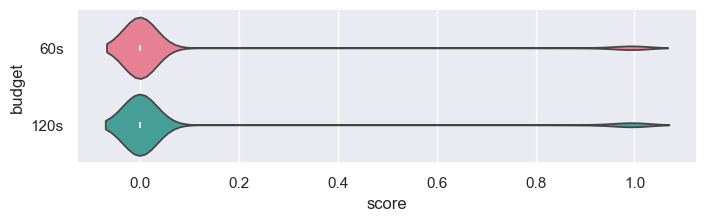

In [149]:
pyplot.rcParams['figure.figsize'] = (8, 2)
plot = pandas.concat([
    leancop_60s_score.to_frame().assign(budget = '60s'),
    leancop_120s_score.to_frame().assign(budget = '120s'),
])
seaborn.violinplot(
    plot,
    x = 'score',
    y = 'budget',
    hue = 'budget',
    palette = 'husl'
)
pyplot.savefig('plots/control_violinplots.png', dpi = 400, bbox_inches = 'tight')

In [102]:
leancop.head()

,status,solved,steps,time_ms,info,error
problem,,,,,,
AGT001+1.p,solved,True,4.0,1.0,NaN,NaN
AGT001+2.p,solved,True,4.0,1.0,NaN,NaN
AGT002+1.p,solved,True,172.0,47.0,NaN,NaN
AGT002+2.p,solved,True,172.0,53.0,NaN,NaN
AGT003+1.p,solved,True,43483.0,14338.0,NaN,NaN


In [98]:
leancop_60s_score

problem
AGT001+1.p    0.983333
AGT001+2.p    0.983333
AGT002+1.p    0.216667
AGT002+2.p    0.116667
AGT003+1.p    0.000000
                ...   
TOP049-1.p    0.000000
TOP050-1.p    0.000000
TOP051-1.p    0.000000
TOP052-1.p    0.000000
TOP053-1.p    0.000000
Name: score, Length: 25775, dtype: float64